In [1]:
import pandas as pd
import numpy as np
import pickle

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

import matplotlib.pyplot as plt

In [2]:
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Saving train.csv to train.csv
Dataset loaded successfully!
Rows and columns: (2000, 14)


,Phone_Weight_g,Rear_Main_Camera_MP,Rear_Camera_Count,Front_Camera_MP,Price_Range_INR,Price_INR,RAM_GB,Storage_GB,Battery_mAh,Display_Size_inches,5G_Support,Dual_SIM,Charger_Wattage_W,ML_Price_Category
0,193,48,3,13,"₹15,000–₹24,999",19500,16,256,6800,6.9,No,No,20,Premium
1,130,13,3,20,"₹15,000–₹24,999",16000,8,128,5000,6.8,Yes,Yes,32,Premium
2,138,50,3,8,"₹25,000–₹39,999",25000,16,256,7200,6.4,Yes,Yes,42,Flagship
3,130,16,2,5,"₹15,000–₹24,999",16500,8,128,5000,6.1,No,No,65,Mid-Range
4,130,13,3,16,"₹5,000–₹9,999",7500,3,64,5500,6.5,No,No,70,Budget


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['Phone_Weight_g', 'Rear_Main_Camera_MP', 'Rear_Camera_Count', 'Front_Camera_MP', 'Price_Range_INR', 'Price_INR', 'RAM_GB', 'Storage_GB', 'Battery_mAh', 'Display_Size_inches', '5G_Support', 'Dual_SIM', 'Charger_Wattage_W', 'ML_Price_Category']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Phone_Weight_g       2000 non-null   int64  
 1   Rear_Main_Camera_MP  2000 non-null   int64  
 2   Rear_Camera_Count    2000 non-null   int64  
 3   Front_Camera_MP      2000 non-null   int64  
 4   Price_Range_INR      2000 non-null   object 
 5   Price_INR            2000 non-null   int64  
 6   RAM_GB               2000 non-null   int64  
 7   Storage_GB           2000 non-null   int64  
 8   Battery_mAh          2000 non-null   int64  
 9   Display_Size_inches  2000 non-null   float64
 10  5G_Suppo

In [5]:
# Display all column names
print("CSV Columns:")
print(df.columns.tolist())

# Display the first 5 rows
print("\nFirst 5 rows:")
display(df.head())

# Display data types
print("\nColumn Data Types:")
print(df.dtypes)

# Find columns related to price
print("\nColumns containing 'price':")
print([
    col for col in df.columns
    if "price" in col.lower()
])

CSV Columns:
['Phone_Weight_g', 'Rear_Main_Camera_MP', 'Rear_Camera_Count', 'Front_Camera_MP', 'Price_Range_INR', 'Price_INR', 'RAM_GB', 'Storage_GB', 'Battery_mAh', 'Display_Size_inches', '5G_Support', 'Dual_SIM', 'Charger_Wattage_W', 'ML_Price_Category']

First 5 rows:


,Phone_Weight_g,Rear_Main_Camera_MP,Rear_Camera_Count,Front_Camera_MP,Price_Range_INR,Price_INR,RAM_GB,Storage_GB,Battery_mAh,Display_Size_inches,5G_Support,Dual_SIM,Charger_Wattage_W,ML_Price_Category
0,193,48,3,13,"₹15,000–₹24,999",19500,16,256,6800,6.9,No,No,20,Premium
1,130,13,3,20,"₹15,000–₹24,999",16000,8,128,5000,6.8,Yes,Yes,32,Premium
2,138,50,3,8,"₹25,000–₹39,999",25000,16,256,7200,6.4,Yes,Yes,42,Flagship
3,130,16,2,5,"₹15,000–₹24,999",16500,8,128,5000,6.1,No,No,65,Mid-Range
4,130,13,3,16,"₹5,000–₹9,999",7500,3,64,5500,6.5,No,No,70,Budget



Column Data Types:
Phone_Weight_g           int64
Rear_Main_Camera_MP      int64
Rear_Camera_Count        int64
Front_Camera_MP          int64
Price_Range_INR         object
Price_INR                int64
RAM_GB                   int64
Storage_GB               int64
Battery_mAh              int64
Display_Size_inches    float64
5G_Support              object
Dual_SIM                object
Charger_Wattage_W        int64
ML_Price_Category       object
dtype: object

Columns containing 'price':
['Price_Range_INR', 'Price_INR', 'ML_Price_Category']


In [6]:
price_range_column = "Price_Range_INR"
price_column = "Price_INR"

print("Output 1:", price_range_column)
print("Output 2:", price_column)

print("\nPrice Range Categories:")
print(df[price_range_column].unique())

print("\nActual Price Examples:")
print(df[price_column].head())

Output 1: Price_Range_INR
Output 2: Price_INR

Price Range Categories:
['₹15,000–₹24,999' '₹25,000–₹39,999' '₹5,000–₹9,999' '₹10,000–₹14,999'
 '₹40,000–₹59,999']

Actual Price Examples:
0    19500
1    16000
2    25000
3    16500
4     7500
Name: Price_INR, dtype: int64


In [7]:
# Remove rows with missing output values
df = df.dropna(
    subset=[price_range_column, price_column]
).copy()

# Remove columns that we want to predict
# Also remove ML_Price_Category to prevent data leakage
X = df.drop(
    columns=[
        "Price_Range_INR",
        "Price_INR",
        "ML_Price_Category"
    ],
    errors="ignore"
)

# First output: price range
y_range = df["Price_Range_INR"]

# Second output: actual phone price
y_price = df["Price_INR"]

print("Input Features:")
print(X.columns.tolist())

print("\nPrice Range Classes:")
print(y_range.unique())

print("\nTotal Records:", len(df))

Input Features:
['Phone_Weight_g', 'Rear_Main_Camera_MP', 'Rear_Camera_Count', 'Front_Camera_MP', 'RAM_GB', 'Storage_GB', 'Battery_mAh', 'Display_Size_inches', '5G_Support', 'Dual_SIM', 'Charger_Wattage_W']

Price Range Classes:
['₹15,000–₹24,999' '₹25,000–₹39,999' '₹5,000–₹9,999' '₹10,000–₹14,999'
 '₹40,000–₹59,999']

Total Records: 2000


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_range_train, y_range_test, y_price_train, y_price_test = train_test_split(
    X,
    y_range,
    y_price,
    test_size=0.20,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 1600
Testing Records: 400


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Process numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Process categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

print("Numerical Features:", numeric_columns)
print("Categorical Features:", categorical_columns)

Numerical Features: ['Phone_Weight_g', 'Rear_Main_Camera_MP', 'Rear_Camera_Count', 'Front_Camera_MP', 'RAM_GB', 'Storage_GB', 'Battery_mAh', 'Display_Size_inches', 'Charger_Wattage_W']
Categorical Features: ['5G_Support', 'Dual_SIM']


In [10]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor

# Model 1: Classification for price range
range_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Model 2: Regression for actual price
price_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

print("Both models created successfully!")

Both models created successfully!


In [11]:
range_model.fit(X_train, y_range_train)

price_model.fit(X_train, y_price_train)

print("Price Range Model Trained!")
print("Price Prediction Model Trained!")

Price Range Model Trained!
Price Prediction Model Trained!


In [12]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

# Predict both outputs
range_pred = range_model.predict(X_test)
price_pred = price_model.predict(X_test)

# Evaluate price range classification
accuracy = accuracy_score(
    y_range_test,
    range_pred
)

print("Price Range Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_range_test,
    range_pred,
    zero_division=0
))

# Evaluate actual price prediction
mae = mean_absolute_error(
    y_price_test,
    price_pred
)

rmse = np.sqrt(mean_squared_error(
    y_price_test,
    price_pred
))

print("\nPrice Prediction MAE:", round(mae, 2), "INR")
print("Price Prediction RMSE:", round(rmse, 2), "INR")

Price Range Accuracy: 42.5 %

Classification Report:
                 precision    recall  f1-score   support

₹10,000–₹14,999       0.20      0.09      0.13        85
₹15,000–₹24,999       0.47      0.66      0.55       172
₹25,000–₹39,999       0.48      0.35      0.41        43
₹40,000–₹59,999       0.00      0.00      0.00         1
  ₹5,000–₹9,999       0.38      0.34      0.36        99

       accuracy                           0.42       400
      macro avg       0.31      0.29      0.29       400
   weighted avg       0.39      0.42      0.40       400


Price Prediction MAE: 5246.83 INR
Price Prediction RMSE: 5973.79 INR


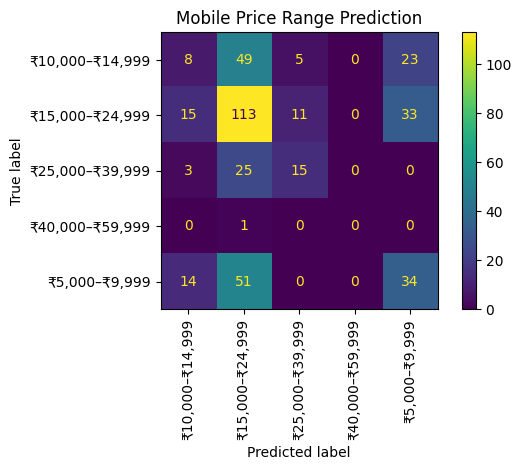

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_range_test,
    range_pred,
    xticks_rotation="vertical"
)

plt.title("Mobile Price Range Prediction")
plt.tight_layout()
plt.show()

In [14]:
import pickle

models = {
    "price_range_model": range_model,
    "price_model": price_model,
    "feature_columns": X.columns.tolist()
}

with open("mobile_price_models.pkl", "wb") as file:
    pickle.dump(models, file)

print("Both models saved successfully!")

Both models saved successfully!


In [15]:
from google.colab import files

files.download("mobile_price_models.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# Select one phone from the test dataset
sample_phone = X_test.iloc[[0]]

# Predict both outputs
predicted_range = range_model.predict(sample_phone)[0]
predicted_price = price_model.predict(sample_phone)[0]

print("MOBILE PRICE PREDICTION")
print("-----------------------")

print("Predicted Price Range:", predicted_range)
print("Predicted Phone Price: ₹", round(predicted_price, 2))

print("\nACTUAL VALUES")
print("Actual Price Range:", y_range_test.iloc[0])
print("Actual Phone Price: ₹", y_price_test.iloc[0])

MOBILE PRICE PREDICTION
-----------------------
Predicted Price Range: ₹15,000–₹24,999
Predicted Phone Price: ₹ 11897.48

ACTUAL VALUES
Actual Price Range: ₹5,000–₹9,999
Actual Phone Price: ₹ 6500
